# Smart Farm Crop & Resource Advisor

**Case study:** Recommend a crop using soil nutrients, weather, and farm-management indicators from Kaggle's Smart Farming Data 2024 (SF24).

This notebook performs the data checks, stratified train/test split, model training, evaluation, and export. Run these cells in Jupyter or Google Colab (the assignment requires training outside VS Code). The exported scikit-learn pipeline includes preprocessing and the fitted estimator in `model.joblib`.

Source: [Kaggle — Smart Farming Data 2024 (SF24)](https://www.kaggle.com/datasets/datasetengineer/smart-farming-data-2024-sf24), CC0.

In [1]:
from pathlib import Path
import json
import joblib
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, ConfusionMatrixDisplay, f1_score
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder

ROOT = Path.cwd()
if not (ROOT / 'data/Crop_recommendationV2.csv').exists():
    ROOT = ROOT.parent
DATA_PATH = ROOT / 'data/Crop_recommendationV2.csv'
assert DATA_PATH.exists(), f'Dataset not found: {DATA_PATH}'
RANDOM_STATE = 42


In [2]:
df = pd.read_csv(DATA_PATH)
TARGET = 'label'
FEATURES = [c for c in df.columns if c != TARGET]
CATEGORICAL = ['soil_type', 'irrigation_frequency', 'growth_stage', 'water_source_type']
NUMERIC = [c for c in FEATURES if c not in CATEGORICAL]

print(f'Shape: {df.shape}')
print(f'Crop classes: {df[TARGET].nunique()}')
print(f'Missing cells: {int(df.isna().sum().sum())}')
display(df.head())
display(df[TARGET].value_counts().rename('samples').to_frame())
assert df[TARGET].notna().all() and df[FEATURES].notna().all().all()


Shape: (2200, 23)
Crop classes: 22
Missing cells: 0


,N,P,K,temperature,humidity,ph,rainfall,label,soil_moisture,soil_type,...,organic_matter,irrigation_frequency,crop_density,pest_pressure,fertilizer_usage,growth_stage,urban_area_proximity,water_source_type,frost_risk,water_usage_efficiency
0,90,42,43,20.879744,82.002744,6.502985,202.935536,rice,29.446064,2,...,3.121395,4,11.743910,57.607308,188.194958,1,2.719614,3,95.649985,1.193293
1,85,58,41,21.770462,80.319644,7.038096,226.655537,rice,12.851183,3,...,2.142021,4,16.797101,74.736879,70.963629,1,4.714427,2,77.265694,1.752672
2,60,55,44,23.004459,82.320763,7.840207,263.964248,rice,29.363913,2,...,1.474974,1,12.654395,1.034478,191.976077,1,30.431736,2,18.192168,3.035541
3,74,35,40,26.491096,80.158363,6.980401,242.864034,rice,26.207732,3,...,8.393907,1,10.864360,24.091888,55.761388,3,10.861071,3,82.818720,1.273341
4,78,42,42,20.130175,81.604873,7.628473,262.717340,rice,28.236236,2,...,5.202285,3,13.852910,38.811481,185.259702,2,47.190777,3,25.466499,2.578671


,samples
label,
rice,100
maize,100
chickpea,100
kidneybeans,100
pigeonpeas,100
mothbeans,100
mungbean,100
blackgram,100
lentil,100


In [3]:
X = df[FEATURES]
y = df[TARGET]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y
)

preprocess = ColumnTransformer([
    ('categorical', OneHotEncoder(handle_unknown='ignore'), CATEGORICAL),
    ('numeric', 'passthrough', NUMERIC),
], remainder='drop')
model = Pipeline([
    ('preprocess', preprocess),
    ('classifier', RandomForestClassifier(
        n_estimators=450, min_samples_leaf=1, class_weight='balanced_subsample',
        random_state=RANDOM_STATE, n_jobs=-1
    )),
])
model.fit(X_train, y_train)


Pipeline(steps=[('preprocess',
                 ColumnTransformer(transformers=[('categorical',
                                                  OneHotEncoder(handle_unknown='ignore'),
                                                  ['soil_type',
                                                   'irrigation_frequency',
                                                   'growth_stage',
                                                   'water_source_type']),
                                                 ('numeric', 'passthrough',
                                                  ['N', 'P', 'K', 'temperature',
                                                   'humidity', 'ph', 'rainfall',
                                                   'soil_moisture',
                                                   'sunlight_exposure',
                                                   'wind_speed',
                                                   'co2_concentration',
                                                   'organic_matter',
                                                   'crop_density',
                                                   'pest_pressure',
                                                   'fertilizer_usage',
                                                   'urban_area_proximity',
                                                   'frost_risk',
                                                   'water_usage_efficiency'])])),
                ('classifier',
                 RandomForestClassifier(class_weight='balanced_subsample',
                                        n_estimators=450, n_jobs=-1,
                                        random_state=42))])

Test accuracy: 0.9977
Test macro F1: 0.9977
              precision    recall  f1-score   support

       apple      1.000     1.000     1.000        20
      banana      1.000     1.000     1.000        20
   blackgram      1.000     1.000     1.000        20
    chickpea      1.000     1.000     1.000        20
     coconut      1.000     1.000     1.000        20
      coffee      1.000     1.000     1.000        20
      cotton      1.000     1.000     1.000        20
      grapes      1.000     1.000     1.000        20
        jute      1.000     1.000     1.000        20
 kidneybeans      1.000     1.000     1.000        20
      lentil      1.000     0.950     0.974        20
       maize      1.000     1.000     1.000        20
       mango      1.000     1.000     1.000        20
   mothbeans      0.952     1.000     0.976        20
    mungbean      1.000     1.000     1.000        20
   muskmelon      1.000     1.000     1.000        20
      orange      1.000     1.000    

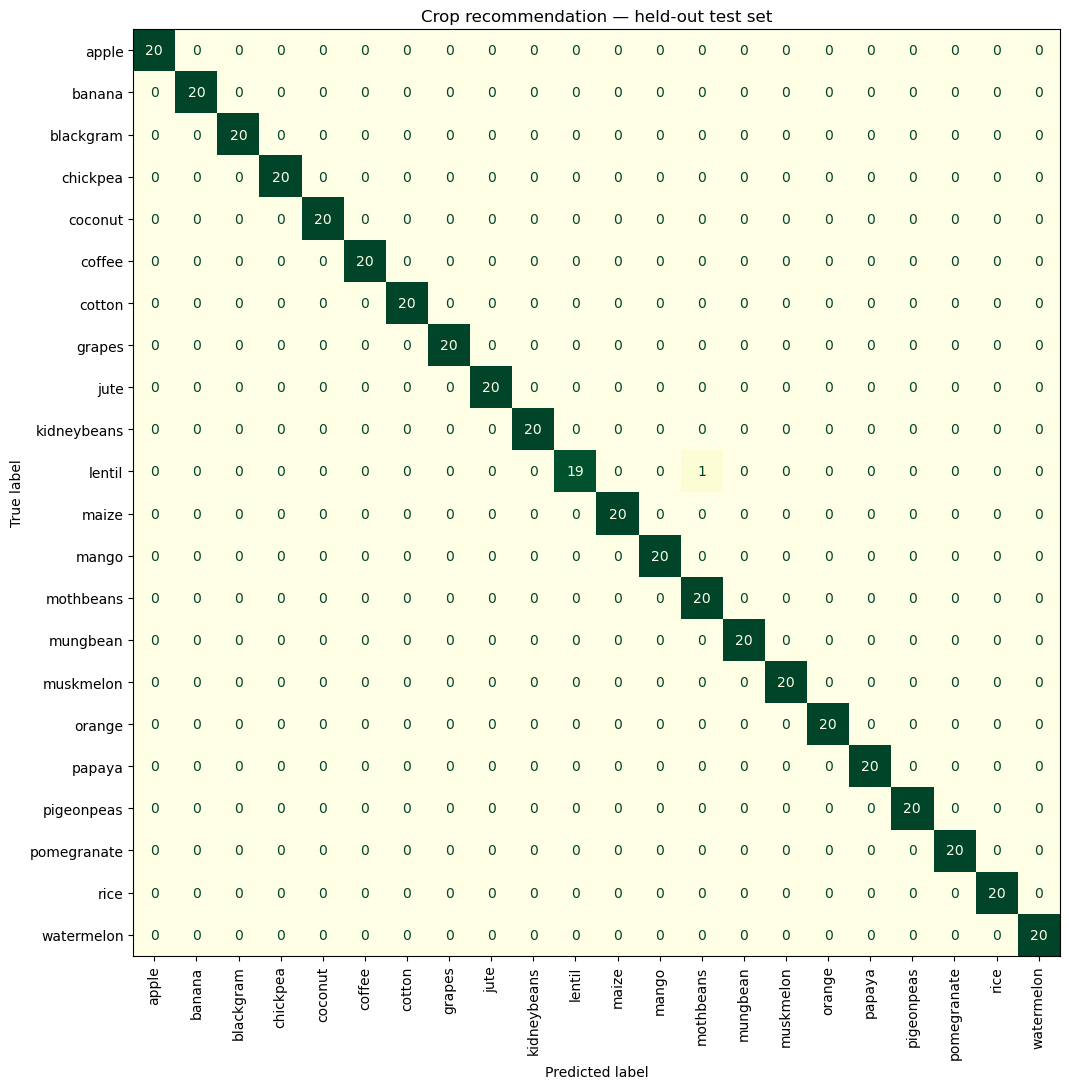

In [4]:
y_pred = model.predict(X_test)
accuracy = float(accuracy_score(y_test, y_pred))
macro_f1 = float(f1_score(y_test, y_pred, average='macro'))
print(f'Test accuracy: {accuracy:.4f}')
print(f'Test macro F1: {macro_f1:.4f}')
print(classification_report(y_test, y_pred, digits=3, zero_division=0))
fig, ax = plt.subplots(figsize=(13, 11))
ConfusionMatrixDisplay.from_predictions(y_test, y_pred, xticks_rotation=90, cmap='YlGn', ax=ax, colorbar=False)
ax.set_title('Crop recommendation — held-out test set')
plt.tight_layout()


In [5]:
# Save the complete fitted pipeline, including one-hot preprocessing and all learned parameters.
model_path = ROOT / 'model.joblib'
joblib.dump(model, model_path, compress=3)
metadata = {
    'model_name': 'RandomForestClassifier',
    'dataset': 'Smart Farming Data 2024 (SF24), Kaggle',
    'dataset_url': 'https://www.kaggle.com/datasets/datasetengineer/smart-farming-data-2024-sf24',
    'target': TARGET,
    'features': FEATURES,
    'categorical_features': CATEGORICAL,
    'numeric_features': NUMERIC,
    'classes': sorted(y.astype(str).unique().tolist()),
    'rows': int(len(df)),
    'train_rows': int(len(X_train)),
    'test_rows': int(len(X_test)),
    'random_state': RANDOM_STATE,
    'test_accuracy': accuracy,
    'test_macro_f1': macro_f1,
    'parameters': model.named_steps['classifier'].get_params(),
}
(ROOT / 'model_metadata.json').write_text(json.dumps(metadata, indent=2, default=str), encoding='utf-8')
print(f'Saved fitted model to {model_path}')
print(f"Saved metrics and model parameters to {ROOT / 'model_metadata.json'}")


Saved fitted model to C:\Users\Admin\Desktop\CA2AiOPS\model.joblib
Saved metrics and model parameters to C:\Users\Admin\Desktop\CA2AiOPS\model_metadata.json


## Interpretation and limits

The reported scores come from a stratified held-out 20% split with a fixed random seed. This dataset is curated for ML practice and includes generated/derived farm attributes; scores measure performance on this dataset's distribution and should not be treated as field-validated agricultural advice. The API's top three class probabilities are relative model scores, not calibrated agronomic probabilities.